K     | Accuracy  
--------------------
1     | 0.9444
2     | 0.9444
3     | 0.9444
4     | 0.9444
5     | 0.9444
6     | 0.9444
7     | 0.9444
8     | 0.9444
9     | 0.9444
10    | 0.9444


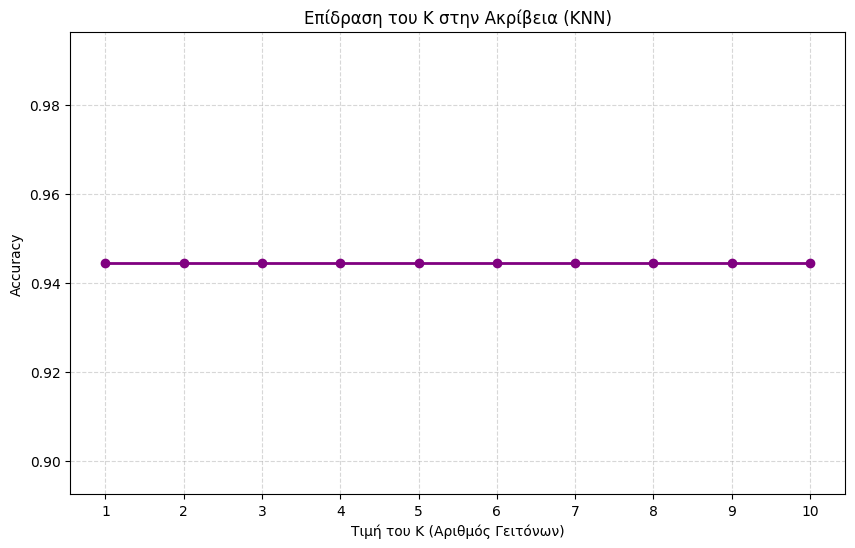


Η βέλτιστη τιμή είναι K = 1 με Accuracy = 0.9444


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from collections import Counter

# =========================================================
# ΒΗΜΑ 4: K-Nearest Neighbors (KNN) - From Scratch
# =========================================================

# 1. Προετοιμασία (Split & Scale)
data = load_wine()
X = data.data
y = data.target

# Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling (ΚΡΙΣΙΜΟ για τον KNN γιατί βασίζεται σε αποστάσεις)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Συνάρτηση Πρόβλεψης για ΕΝΑ δείγμα
def knn_predict_single(x_test_sample, X_train, y_train, k):
    """
    Προβλέπει την κλάση για ένα δείγμα (x_test_sample)
    βασιζόμενο στους k κοντινότερους γείτονες από το X_train.
    """
    # Α. Υπολογισμός Ευκλείδειας Απόστασης από ΟΛΑ τα σημεία του Train
    # Χρησιμοποιούμε NumPy broadcasting για ταχύτητα
    # distance = sqrt( sum( (x1 - x2)^2 ) )
    distances = np.sqrt(np.sum((X_train - x_test_sample)**2, axis=1))
    
    # Β. Εύρεση των K κοντινότερων γειτόνων
    # Η argsort επιστρέφει τους δείκτες ταξινομημένους από τον μικρότερο στον μεγαλύτερο
    k_indices = np.argsort(distances)[:k]
    
    # Γ. Ανάκτηση των labels των γειτόνων
    k_nearest_labels = y_train[k_indices]
    
    # Δ. Ψηφοφορία (Majority Vote)
    # Βρίσκουμε το πιο συχνό label
    most_common = Counter(k_nearest_labels).most_common(1)
    return most_common[0][0]

# 3. Συνάρτηση Πρόβλεψης για ΟΛΟ το Test Set
def knn_predict(X_test, X_train, y_train, k):
    predictions = []
    for x_sample in X_test:
        pred = knn_predict_single(x_sample, X_train, y_train, k)
        predictions.append(pred)
    return np.array(predictions)

# 4. Πειραματισμός για K = 1 έως 10
k_values = range(1, 11)
accuracies = []

print(f"{'K':<5} | {'Accuracy':<10}")
print("-" * 20)

for k in k_values:
    # Πρόβλεψη
    y_pred = knn_predict(X_test_scaled, X_train_scaled, y_train, k)
    
    # Αξιολόγηση
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    
    print(f"{k:<5} | {acc:.4f}")

# 5. Οπτικοποίηση Αποτελεσμάτων
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='purple', linewidth=2)
plt.title('Επίδραση του Κ στην Ακρίβεια (KNN)')
plt.xlabel('Τιμή του K (Αριθμός Γειτόνων)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Εύρεση του βέλτιστου K
best_k = k_values[np.argmax(accuracies)]
print(f"\nΗ βέλτιστη τιμή είναι K = {best_k} με Accuracy = {max(accuracies):.4f}")